# Занятие 21 (дополнение). Честный ML workflow на новом датасете: kNN и категориальные признаки

Теоретический ноутбук-пример для работы **у доски**: тот же цикл, что на уроке, но на другом датасете — **Titanic** (реальные данные: категориальные признаки, пропуски, дублирующие колонки и колонка-утечка).

Канва — ноутбук урока: вопросы **Обсудим** — для диалога с классом, блоки **Вывод** — то, что фиксируем после обсуждения. Заданий для студентов здесь нет, только разбор примера.

К концу фиксируем:

- как категориальные признаки превращаются в числа для kNN и почему порядок шагов важен;
- как отличить «честный» workflow от нечестного — и **увидеть** разницу на цифрах;
- kNN vs baseline на validation, подбор `k` по validation, **один раз** test.

## 1. Тип задачи и датасет

Данные о пассажирах «Титаника». Для каждого пассажира известны класс каюты, пол, возраст, состав семьи на борту, цена билета, порт посадки — и **известно, выжил ли он**.

| Задача | Есть метки? | Что предсказываем? |
|---|---|---|
| кластеризация | нет | группы похожих объектов |
| классификация | да | категорию |
| регрессия | да | число |

**Обсудим:** в нашем датасете метка — «выжил / не выжил». Классификация или регрессия? С учителем или без?

> **Вывод.** Метки есть, ответ — категория → **классификация с учителем**. Новое по сравнению с уроком: среди **признаков** теперь есть не только числа, но и **категории** (пол, класс каюты, порт). kNN считает расстояния, поэтому категории придётся превратить в числа — и сделать это честно.

## 2. Сквозной цикл и «закон» честного workflow

1. Постановка → 2. Аудит данных → 3. Split → 4. Baseline → 5. Предобработка (fit на train) → 6. Эксперименты на validation → 7. Подбор `k` на validation → 8. Проверка критерия → 9. Анализ ошибок → **один раз test** → 10. Выводы и мониторинг.

| Действие | Train | Validation | Test |
|---|:---:|:---:|:---:|
| `fit` импутера / энкодера / scaler / модели | ✅ | ❌ | ❌ |
| `transform` / `predict` | ✅ | ✅ | ✅ (только финал) |
| Выбор признаков, кодирования, `k` | ❌ | ✅ | ❌ |
| Финальная оценка выбранного решения | ❌ | ❌ | ✅ **один раз** |

**Обсудим:** на каком шаге вы будете крутить `k` и сравнивать способы кодирования? Где «живёт» test?

> **Вывод.** Workflow — **цикл**. Идеи, кодирование и `k` сравниваем на **validation**; **test** — финал уже выбранного решения.

## 3. Данные

Загружаем таблицу. Если нет интернета — используется локальный файл `titanic.csv` рядом с ноутбуком (он приложен к ноутбуку).

In [1]:
import numpy as np
import pandas as pd

URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv'
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv('titanic.csv')

print('Строк:', df.shape[0], '| колонок:', df.shape[1])
print('Доля выживших (survived = 1):', round(df['survived'].mean(), 3))
df.head()

Строк: 891 | колонок: 15
Доля выживших (survived = 1): 0.384


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Обсудим:** что в таблице категории, что числа? Что за пропуски видно сразу?

> **Вывод.** Данные — «живые»: есть пропуски, категории, а колонок больше, чем нужно. Прежде чем обучать модель, проводим **аудит**.

## 4. От вопроса к ML-задаче (до просмотра результатов!)

**Обсудим:** «кто из пассажиров в опасности?» — уже ML-задача? Чего не хватает?

| Пункт | В нашем примере |
|---|---|
| объект | один пассажир (строка) |
| момент прогноза | посадка на борт: известно только то, что записано в билете и списке пассажиров, **без исхода** |
| цель | класс 0 — **не выжил**, класс 1 — выжил |
| действие | пассажиру с прогнозом 0 заранее назначают помощь при эвакуации |
| главная метрика | **recall класса 0**: доля найденных пассажиров, которым нужна помощь (`pos_label=0`) |
| контрольная метрика | **precision класса 0**: доля настоящих «рисковых» среди тех, кому назначена помощь |
| критерий успеха (фиксируем сейчас) | на validation: **recall(0) ≥ 0,85 и precision(0) ≥ 0,80** |

> Учебная пометка: это исторический датасет; мы тренируем **процедуру**, а не «предсказываем судьбу» реальных людей.

**Обсудим:** почему критерий записывают **до** экспериментов? Зачем пара метрик, если «опасных» нужно найти как можно больше?

> **Вывод.** Объект, момент, цель, действие, метрика и **критерий успеха** — до просмотра цифр. Контрольная метрика не даёт «купить» recall ценой бесконечных ложных тревог: модель «всем назначить помощь» имеет recall = 1.

## 5. Аудит колонок: что можно использовать на момент прогноза?

**Обсудим:** по таблице ниже определите колонки, которые **нельзя** использовать как признаки, и колонки, которые дублируют друг друга.

| Колонка | Что это | Комментарий |
|---|---|---|
| `survived` | цель | её мы предсказываем |
| `alive` | «yes / no» | текстовая копия цели → **утечка** |
| `pclass`, `class` | класс каюты числом и словом | дубль; берём одну (`pclass`) |
| `embarked`, `embark_town` | порт посадки кодом и названием | дубль; берём одну (`embarked`) |
| `sex`, `who`, `adult_male` | пол / «мужчина, женщина, ребёнок» / флаг | `who` и `adult_male` — **производные** от пола и возраста; берём исходные `sex` и `age` |
| `sibsp`, `parch`, `alone` | родственники на борту | `alone` выводится из `sibsp` и `parch` |
| `deck` | палуба | ~77 % пропусков: как признак малополезна без отдельной гипотезы |
| `age`, `fare` | число | возраст с пропусками |

In [2]:
# Аудит структуры (цель и качество колонок), без обучения моделей
print('Доля пропусков по колонкам:')
print(df.isna().mean().round(3).sort_values(ascending=False).head(4).to_string())

print('\nsurvived × alive:')
display(pd.crosstab(df['survived'], df['alive']))

print('\nМожно ли получить class из pclass?')
display(pd.crosstab(df['pclass'], df['class']))

print('\nЧисло уникальных значений категориальных колонок:')
for c in ['sex', 'embarked', 'pclass']:
    print(c, '->', df[c].dropna().nunique(), sorted(df[c].dropna().unique().tolist()))

Доля пропусков по колонкам:
deck           0.772
age            0.199
embarked       0.002
embark_town    0.002

survived × alive:


alive,no,yes
survived,,
0,549,0
1,0,342



Можно ли получить class из pclass?


class,First,Second,Third
pclass,,,
1,216,0,0
2,0,184,0
3,0,0,491



Число уникальных значений категориальных колонок:
sex -> 2 ['female', 'male']
embarked -> 3 ['C', 'Q', 'S']
pclass -> 3 [1, 2, 3]


**Обсудим:** по таблице `survived × alive` — что будет, если оставить `alive` в признаках? Будет ли такая модель работать в реальном прогнозе?

> **Вывод.** `alive` — это сама цель, записанная словами: на момент прогноза её **нет**. Колонки исключаем по **смыслу** (момент прогноза, дубли), а не потому что «так выше метрика».

## 6. Признаки и их типы

Итоговый набор признаков и роль каждого для kNN:

| Тип | Признаки | Как готовим |
|---|---|---|
| числовые | `age`, `sibsp`, `parch`, `fare` | заполнить пропуски медианой → стандартизировать |
| порядковые | `pclass` (1 < 2 < 3 по классу каюты) | порядок задан явно → стандартизировать |
| номинальные | `sex`, `embarked` | пропуски → `unknown` → one-hot |

**Обсудим:** почему `embarked` нельзя закодировать числами 0, 1, 2? (Что «подумает» расстояние?)

In [3]:
target = 'survived'
num_cols = ['age', 'sibsp', 'parch', 'fare']
ord_cols = ['pclass']
nom_cols = ['sex', 'embarked']
feature_cols = num_cols + ord_cols + nom_cols

X = df[feature_cols].copy()
y = df[target]
print('Признаков:', X.shape[1], '|', feature_cols)

Признаков: 7 | ['age', 'sibsp', 'parch', 'fare', 'pclass', 'sex', 'embarked']


> **Вывод.** Для kNN каждый столбец должен стать **числом без пропусков в сопоставимом масштабе**. Порядковые категории — числа с явным порядком; номинальные — one-hot (все значения равноудалены друг от друга).

## 7. Независимость объектов и способ разбиения

| Сценарий | Как делить |
|---|---|
| объекты независимы | случайно |
| несколько строк на одного человека / семью | вся группа в одной части |
| прогноз будущего | по времени |

**Обсудим:** наш датасет — какой сценарий? Пассажиры одной семьи (`sibsp`, `parch`) — независимы? Что сломается, если муж в train, а жена в test?

> **Вывод.** Split повторяет то, что будет **новым** после внедрения. Здесь мы принимаем случайный стратифицированный split, но честно фиксируем **ограничение**: родственники похожи (одна каюта, один билет), и в идеале делили бы по семьям. В колонках seaborn-версии нет фамилии — поэтому оставляем случайный split и записываем это в выводы проекта.

## 8. Train, validation и test

Делим **до** любых статистик: 60 / 20 / 20, со `stratify` (сохраняем долю классов) и фиксированным `random_state`.

In [4]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print('train / val / test:', len(X_train), len(X_val), len(X_test))
for name, part in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(name, 'доля выживших:', round(part.mean(), 3))

train / val / test: 534 178 179
train доля выживших: 0.384
val доля выживших: 0.382
test доля выживших: 0.385


**Обсудим:** зачем `stratify=y`? Почему сначала делим, и только потом заполняем пропуски в `age`?

> **Вывод.** Validation — для экспериментов; test после выбора **не крутят**. Любая статистика (медиана, среднее, σ, список категорий) считается **только на train**.

## 9. Baseline: с чем сравнивать kNN

**Обсудим:** что сделает `DummyClassifier(strategy='most_frequent')` и какие у него будут recall и precision класса 0?

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix

def metrics0(y_true, y_pred):
    # главная и контрольная метрики для класса 0 (не выжил)
    return {
        'acc': round(accuracy_score(y_true, y_pred), 3),
        'recall_0': round(recall_score(y_true, y_pred, pos_label=0), 3),
        'precision_0': round(precision_score(y_true, y_pred, pos_label=0, zero_division=0), 3),
    }

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_pred = dummy.predict(X_val)
print('Baseline на validation:', metrics0(y_val, dummy_pred))
print('Доля большего класса в train:', round(1 - y_train.mean(), 3))

Baseline на validation: {'acc': 0.618, 'recall_0': 1.0, 'precision_0': 0.618}
Доля большего класса в train: 0.616


**Обсудим:** у baseline recall класса 0 равен 1 — он «нашёл» всех рисковых. Значит ли это, что он хорош? Что показывает precision?

> **Вывод.** Baseline — ориентир. Accuracy ≈ доле частого класса. Recall = 1 получен тривиально («помощь всем»), поэтому **критерий из двух метрик** baseline не проходит: precision(0) всего ≈ доле класса 0.

## 10. Метрика следует из цены ошибок

| | Прогноз «не выжил» (0) | Прогноз «выжил» (1) |
|---|---|---|
| **Истина 0** | **TP** | **FN** (пропуск!) |
| **Истина 1** | **FP** (ложная тревога) | **TN** |

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad \mathrm{precision}=\frac{TP}{TP+FP}$$

**Обсудим:** `pos_label=0` — слово «positive» значит «хороший класс»? Чьи ошибки дороже в нашей постановке — FN или FP?

> **Вывод.** `pos_label` — «про какой класс считаем»; у нас это **0 (не выжил)**. Recall — сколько рисковых нашли, precision — сколько тревог настоящие. Цена ошибки задаёт главную метрику.

## 11. Предобработка как единый pipeline

Одна функция собирает `ColumnTransformer` из трёх веток. Всё, что «учится» (медиана, порядок категорий, среднее и σ, список категорий), учится на `fit` — а `fit` вызываем **только на train**.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier

ORDER = {'pclass': [1, 2, 3]}

def make_preprocessor(num, ord_, nom, scale=True):
    parts = []
    if num:
        steps = [('imputer', SimpleImputer(strategy='median'))]
        if scale:
            steps.append(('scaler', StandardScaler()))
        parts.append(('num', Pipeline(steps), num))
    if ord_:
        steps = [
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(categories=[ORDER[c] for c in ord_])),
        ]
        if scale:
            steps.append(('scaler', StandardScaler()))
        parts.append(('ord', Pipeline(steps), ord_))
    if nom:
        steps = [
            ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
            ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ]
        parts.append(('nom', Pipeline(steps), nom))
    return ColumnTransformer(parts)

prep = make_preprocessor(num_cols, ord_cols, nom_cols)
Z_train = prep.fit_transform(X_train)      # fit ТОЛЬКО на train
Z_val = prep.transform(X_val)
print('train:', Z_train.shape, '| val:', Z_val.shape)
print('Признаки после преобразования:')
print(list(prep.get_feature_names_out()))

train: (534, 11) | val: (178, 11)
Признаки после преобразования:
['num__age', 'num__sibsp', 'num__parch', 'num__fare', 'ord__pclass', 'nom__sex_female', 'nom__sex_male', 'nom__embarked_C', 'nom__embarked_Q', 'nom__embarked_S', 'nom__embarked_unknown']


**Обсудим:** почему столбцов стало больше, чем было признаков? Что раньше — `fit` препроцессора или `fit` модели?

> **Вывод.** `sex` стал двумя столбцами (`female`, `male`), `embarked` — несколькими (в том числе `unknown` для пропусков). Сначала преобразования (fit на train), потом модель.

## 12. Что именно «выучил» препроцессор — и откуда

**Обсудим:** на какой выборке посчитана медиана возраста для заполнения пропусков? Изменится ли она, если считать по всей таблице?

In [7]:
imp = prep.named_transformers_['num'].named_steps['imputer']
print('Медиана age, посчитанная на train :', imp.statistics_[0])
print('Медиана age по ВСЕЙ таблице       :', float(X['age'].median()))

scaler = prep.named_transformers_['num'].named_steps['scaler']
print('\nСреднее fare, выученное на train   :', round(float(scaler.mean_[3]), 3))
print('Среднее fare на validation         :', round(float(X_val['fare'].mean()), 3))

cats = prep.named_transformers_['nom'].named_steps['encoder'].categories_
print('\nКатегории, которые видел энкодер на train:')
print(' sex     :', list(cats[0]))
print(' embarked:', list(cats[1]))

# неизвестная категория не должна ломать transform
row = X_val.iloc[[0]].copy()
row['embarked'] = 'Z'     # порт, которого не было в train
print('\ntransform с неизвестной категорией — shape:', prep.transform(row).shape)

Медиана age, посчитанная на train : 29.0
Медиана age по ВСЕЙ таблице       : 28.0

Среднее fare, выученное на train   : 31.247
Среднее fare на validation         : 33.539

Категории, которые видел энкодер на train:
 sex     : ['female', 'male']
 embarked: ['C', 'Q', 'S', 'unknown']

transform с неизвестной категорией — shape: (1, 11)


> **Вывод.** Все параметры препроцессора — из **train**. `handle_unknown='ignore'` нужен, чтобы новая категория (в validation, test или в реальной эксплуатации) не ломала код: для неё one-hot-столбцы этого признака будут нулями.

## 13. Что «видит» kNN: вклад признаков в расстояние

Расстояние — $d(a,b)=\sqrt{\sum_j (a_j-b_j)^2}$. Возьмём двух разных пассажиров и посмотрим, **какой признак вносит наибольший вклад** в расстояние между ними — без масштабирования и со стандартизацией.

**Обсудим:** если один признак измеряется в десятках («fare» — цена билета), а другой — в единицах («parch»), кто будет решать, кто «ближайший сосед»?

In [8]:
i1 = X_train[(X_train['sex'] == 'female') & (X_train['pclass'] == 1)].index[0]
i2 = X_train[(X_train['sex'] == 'male') & (X_train['pclass'] == 3)].index[0]
pair = X_train.loc[[i1, i2]]
display(pair)

def contributions(preprocessor, pair_df):
    Z = preprocessor.transform(pair_df)
    Z = Z.toarray() if hasattr(Z, 'toarray') else Z
    names = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]
    contrib = (Z[0] - Z[1]) ** 2
    return pd.Series(contrib, index=names).round(2)

prep_raw = make_preprocessor(num_cols, ord_cols, nom_cols, scale=False).fit(X_train)
prep_std = make_preprocessor(num_cols, ord_cols, nom_cols, scale=True).fit(X_train)

cmp = pd.DataFrame({
    'вклад без scaler': contributions(prep_raw, pair),
    'вклад со scaler': contributions(prep_std, pair),
})
display(cmp)
print('Доля fare в d² без scaler:', round(cmp.loc['fare', 'вклад без scaler'] / cmp['вклад без scaler'].sum(), 3))
print('Доля fare в d² со scaler :', round(cmp.loc['fare', 'вклад со scaler'] / cmp['вклад со scaler'].sum(), 3))

,age,sibsp,parch,fare,pclass,sex,embarked
577,39.0,1,0,55.9,1,female,S
63,4.0,3,2,27.9,3,male,S


,вклад без scaler,вклад со scaler
age,1225.0,7.13
sibsp,4.0,3.46
parch,4.0,5.44
fare,784.0,0.37
pclass,4.0,5.78
sex_female,1.0,1.00
sex_male,1.0,1.00
embarked_C,0.0,0.00
embarked_Q,0.0,0.00
embarked_S,0.0,0.00


Доля fare в d² без scaler: 0.388
Доля fare в d² со scaler : 0.015


**Обсудим:** какие признаки без scaler вообще «не слышны» в расстоянии? Какую роль играет one-hot для `sex`?

> **Вывод.** Без масштабирования расстоянием правит признак с самыми большими числами (`fare`, `age`), а пол, класс и семья почти не участвуют. Стандартизация выравнивает вклады; one-hot даёт категориям сопоставимый «вес» 0/1.

## 14. Первая модель: kNN против baseline

**Обсудим:** что раньше — `fit` препроцессора или `fit` kNN? Достаточно ли одной accuracy?

In [9]:
def build_model(num, ord_, nom, scale=True, k=5):
    return Pipeline([
        ('prep', make_preprocessor(num, ord_, nom, scale=scale)),
        ('knn', KNeighborsClassifier(n_neighbors=k)),
    ])

model = build_model(num_cols, ord_cols, nom_cols, scale=True, k=5).fit(X_train, y_train)
val_pred = model.predict(X_val)
print('kNN (k=5) на validation:', metrics0(y_val, val_pred))
print('Baseline               :', metrics0(y_val, dummy_pred))

kNN (k=5) на validation: {'acc': 0.837, 'recall_0': 0.882, 'precision_0': 0.858}
Baseline               : {'acc': 0.618, 'recall_0': 1.0, 'precision_0': 0.618}


> **Вывод.** `Pipeline` гарантирует порядок «преобразования → модель» и то, что `fit` препроцессора видит только train. Лучше baseline по accuracy и precision — это уже сигнал; решаем по полному журналу.

## 15. Инжиниринг признаков и журнал экспериментов

Новый столбец из **уже известных** чисел — легальный приём: `family_size = sibsp + parch + 1` (сам пассажир + родственники на борту). Он не использует ни цель, ни статистики по всей таблице.

Журнал: один split, одни метрики, **одно** изменение за раз.

| ID | Гипотеза | Что меняем |
|---|---|---|
| H1 | только числовые признаки | — |
| H2 | + `pclass` (ordinal) и `sex`, `embarked` (one-hot) | добавили категории |
| H3 | `pclass` кодируем one-hot вместо ordinal | способ кодирования |
| H4 | как H2, без масштабирования | убрали scaler |
| H5 | как H2 + `family_size` | добавили новый признак |

**Обсудим:** почему в журнале H3 отличается от H2 только кодированием `pclass`?

In [10]:
def add_features(frame):
    out = frame.copy()
    out['family_size'] = out['sibsp'] + out['parch'] + 1
    return out

X_train_fe, X_val_fe, X_test_fe = add_features(X_train), add_features(X_val), add_features(X_test)

def run_experiment(name, num, ord_, nom, scale, k):
    m = build_model(num, ord_, nom, scale=scale, k=k).fit(X_train_fe, y_train)
    return {'эксперимент': name, 'k': k, **{f'val_{a}': b for a, b in metrics0(y_val, m.predict(X_val_fe)).items()}}

journal = [{'эксперимент': 'Baseline (most_frequent)', 'k': None,
            **{f'val_{a}': b for a, b in metrics0(y_val, dummy_pred).items()}}]
journal += [
    run_experiment('H1: только числа', num_cols, [], [], True, 5),
    run_experiment('H2: + pclass(ord) + sex, embarked(one-hot)', num_cols, ord_cols, nom_cols, True, 5),
    run_experiment('H3: pclass как one-hot', num_cols, [], nom_cols + ord_cols, True, 5),
    run_experiment('H4: как H2, без scaler', num_cols, ord_cols, nom_cols, False, 5),
    run_experiment('H5: как H2 + family_size', num_cols + ['family_size'], ord_cols, nom_cols, True, 5),
]
journal_df = pd.DataFrame(journal)
journal_df

,эксперимент,k,val_acc,val_recall_0,val_precision_0
0,Baseline (most_frequent),NaN,0.618,1.000,0.618
1,H1: только числа,5.0,0.685,0.755,0.741
2,"H2: + pclass(ord) + sex, embarked(one-hot)",5.0,0.837,0.882,0.858
3,H3: pclass как one-hot,5.0,0.837,0.882,0.858
4,"H4: как H2, без scaler",5.0,0.708,0.764,0.764
5,H5: как H2 + family_size,5.0,0.837,0.864,0.872


**Обсудим:** что дали категориальные признаки (H1 → H2)? Заметна ли разница между H2 и H3, H5? Можно ли по разнице в 1–2 пункта на выборке из ~180 объектов делать твёрдый вывод?

> **Вывод.** Категории (пол, класс) несут основную часть сигнала; без масштабирования модель резко хуже. Малые различия между близкими гипотезами на маленьком validation — в пределах случайности: проверять их стоит на нескольких разбиениях **внутри train** (кросс-валидация), а не на test.

## 16. Подбор `k` по validation

Правило выбора фиксируем **заранее**: среди `k`, у которых `precision(0) ≥ 0,80`, берём `k` с максимальным `recall(0)`; при равенстве — больший `k` (более гладкая модель).

**Обсудим:** что будет при очень маленьком `k`? При очень большом?

,эксперимент,k,val_acc,val_recall_0,val_precision_0
0,"kNN, k=1",1,0.764,0.791,0.821
1,"kNN, k=3",3,0.826,0.873,0.850
2,"kNN, k=5",5,0.837,0.882,0.858
3,"kNN, k=7",7,0.815,0.873,0.835
4,"kNN, k=11",11,0.843,0.909,0.847
5,"kNN, k=15",15,0.848,0.909,0.855
6,"kNN, k=21",21,0.837,0.918,0.835
7,"kNN, k=31",31,0.826,0.891,0.838
8,"kNN, k=41",41,0.815,0.909,0.813


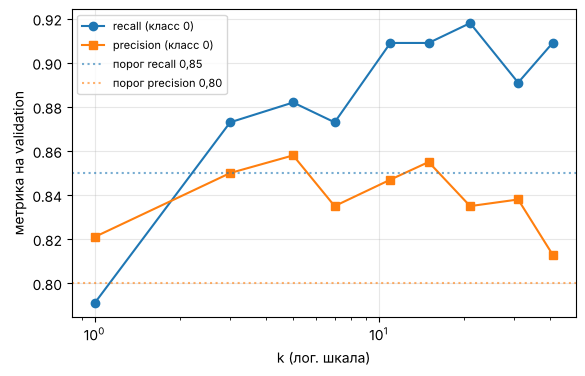

Выбрано по validation: k = 21


In [11]:
import matplotlib.pyplot as plt

K_GRID = [1, 3, 5, 7, 11, 15, 21, 31, 41]
k_df = pd.DataFrame([run_experiment(f'kNN, k={k}', num_cols, ord_cols, nom_cols, True, k) for k in K_GRID])
display(k_df)

plt.figure(figsize=(6.5, 4))
plt.plot(k_df['k'], k_df['val_recall_0'], marker='o', label='recall (класс 0)')
plt.plot(k_df['k'], k_df['val_precision_0'], marker='s', label='precision (класс 0)')
plt.axhline(0.85, color='tab:blue', linestyle=':', alpha=0.6, label='порог recall 0,85')
plt.axhline(0.80, color='tab:orange', linestyle=':', alpha=0.6, label='порог precision 0,80')
plt.xscale('log'); plt.xlabel('k (лог. шкала)'); plt.ylabel('метрика на validation')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

candidates = k_df[k_df['val_precision_0'] >= 0.80]
best_row = candidates.sort_values(['val_recall_0', 'k'], ascending=[False, False]).iloc[0]
best_k = int(best_row['k'])
print('Выбрано по validation: k =', best_k)

> **Вывод.** `k` — гиперпараметр, его выбираем по **validation** и по метрике задачи с учётом контрольной. Маленький `k` — шумная модель (реагирует на единичных соседей), большой — слишком гладкая (приближается к baseline).

## 17. Проверка критерия успеха на validation

**Обсудим:** если критерий не выполнен — что допустимо делать, а что нет?

In [12]:
final_model = build_model(num_cols, ord_cols, nom_cols, scale=True, k=best_k).fit(X_train_fe, y_train)
val_pred = final_model.predict(X_val_fe)
m = metrics0(y_val, val_pred)
print(f'k={best_k}, validation:', m)
ok = m['recall_0'] >= 0.85 and m['precision_0'] >= 0.80
print('Критерий успеха (recall(0) ≥ 0,85 и precision(0) ≥ 0,80):', 'выполнен' if ok else 'НЕ выполнен')

k=21, validation: {'acc': 0.837, 'recall_0': 0.918, 'precision_0': 0.835}
Критерий успеха (recall(0) ≥ 0,85 и precision(0) ≥ 0,80): выполнен


> **Вывод.** Решение «годится / не годится» принимаем **на validation**, до test. Если критерий не выполнен, допустимо вернуться к гипотезам и честно сообщить результат; **недопустимо** двигать планку, подбирать `k` или признаки по test, «тихо» смотреть test.

## 18. Матрица ошибок и разбор по группам

**Обсудим:** что строки и столбцы в матрице ошибок? Где FN — пропущенные рисковые пассажиры? Должны ли доли recall по группам «мужчины» и «женщины» складываться в 1?

In [13]:
cm = confusion_matrix(y_val, val_pred, labels=[0, 1])
display(pd.DataFrame(cm, index=['истина 0 (не выжил)', 'истина 1 (выжил)'],
                     columns=['прогноз 0', 'прогноз 1']))
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print('TP, FN, FP, TN (класс 0):', int(tp), int(fn), int(fp), int(tn))

err = pd.DataFrame({'sex': X_val['sex'].to_numpy(), 'pclass': X_val['pclass'].to_numpy(),
                    'y': y_val.to_numpy(), 'pred': val_pred})
def group_report(col):
    rows = []
    for g, part in err.groupby(col):
        pos = part[part['y'] == 0]
        rows.append({col: g, 'пассажиров': len(part), 'не выжили': len(pos),
                     'recall_0': round((pos['pred'] == 0).mean(), 3) if len(pos) else float('nan'),
                     'доля ошибок': round((part['pred'] != part['y']).mean(), 3)})
    return pd.DataFrame(rows)
display(group_report('sex'))
display(group_report('pclass'))

,прогноз 0,прогноз 1
истина 0 (не выжил),101,9
истина 1 (выжил),20,48


TP, FN, FP, TN (класс 0): 101 9 20 48


,sex,пассажиров,не выжили,recall_0,доля ошибок
0,female,64,16,0.688,0.141
1,male,114,94,0.957,0.175


,pclass,пассажиров,не выжили,recall_0,доля ошибок
0,1,43,17,0.706,0.256
1,2,36,15,0.933,0.083
2,3,99,78,0.962,0.152


**Обсудим:** в какой группе модель хуже находит рисковых? Хватает ли в группе объектов, чтобы доверять доле?

> **Вывод.** Матрица показывает **какие** ошибки, не только среднее. Доли по группам считаются внутри группы и в 1 не складываются; в малых группах оценка неустойчива. В нашем запуске recall(0) заметно ниже у женщин (≈ 0,69) и у пассажиров 1 класса (≈ 0,71) — но «не выживших» в этих группах всего 16 и 17 человек, поэтому это **гипотеза** для следующего цикла (например, добавить признаки взаимодействия «пол × класс»), а не повод подкрутить модель по test.

## 19. Финальный test и внедрение

**Обсудим:** после того как вы увидели test-метрики, можно ещё покрутить `k` и снова глянуть test?

Конфигурация зафиксирована: признаки H2, `StandardScaler` на train, `k = best_k`. Считаем test **один раз**.

In [14]:
test_pred = final_model.predict(X_test_fe)
mt = metrics0(y_test, test_pred)
print(f'Финальные метрики kNN (k={best_k}) на test:', mt)
print('Baseline на validation был:', metrics0(y_val, dummy_pred))
print('Критерий на test:', 'выполнен' if (mt['recall_0'] >= 0.85 and mt['precision_0'] >= 0.80) else 'НЕ выполнен')

Финальные метрики kNN (k=21) на test: {'acc': 0.771, 'recall_0': 0.882, 'precision_0': 0.776}
Baseline на validation был: {'acc': 0.618, 'recall_0': 1.0, 'precision_0': 0.618}
Критерий на test: НЕ выполнен


**Обсудим:** в нашем запуске на validation критерий был выполнен, а на test — нет (recall держится, но precision(0) ≈ 0,78 оказался ниже порога 0,80). Что с этим делать? Можно ли «поправить `k`» и пересчитать test?

> **Вывод.** Выбрали по validation → **один раз** test → test не трогаем. Расхождение validation и test — типичная случайная вариация на выборках по ~180 объектов (пара ложных тревог меняет precision на несколько пунктов). Честный итог: **критерий на test не подтверждён**; это записываем в выводы проекта и планируем новый цикл (новые гипотезы на validation, более надёжная оценка через кросс-валидацию на train, больше данных). Подкрутка `k` по test превратила бы test в validation и лишила бы нас независимой проверки. После внедрения смотрят дрейф данных (доли категорий, новые значения) и качество: мир меняется.

## 20. Как выглядит нечестный workflow и почему метрика «врёт»

Ниже — **демонстрации того, чего делать нельзя**. Цель — увидеть эффект, а не использовать эти приёмы.

### 20.1. Утечка из будущего: колонка `alive`
**Обсудим:** что произойдёт с метриками, если добавить `alive` в признаки?

In [15]:
# ❌ ТОЛЬКО ДЕМОНСТРАЦИЯ: признак `alive` — текстовая копия цели
X_train_leak = X_train_fe.join(df['alive'])
X_val_leak = X_val_fe.join(df['alive'])
leak_model = build_model(num_cols, ord_cols, nom_cols + ['alive'], scale=True, k=best_k).fit(X_train_leak, y_train)
print('С утечкой (validation):', metrics0(y_val, leak_model.predict(X_val_leak)))
print('Честно    (validation):', metrics0(y_val, val_pred))

С утечкой (validation): {'acc': 0.978, 'recall_0': 0.973, 'precision_0': 0.991}
Честно    (validation): {'acc': 0.837, 'recall_0': 0.918, 'precision_0': 0.835}


> **Вывод.** Почти идеальные метрики — повод **искать утечку**, а не праздновать. В реальном прогнозе `alive` не существует, и качество упадёт до честного.

### 20.2. Подбор `k` по test
**Обсудим:** если выбрать `k` с лучшим test-recall и назвать его «финальной оценкой», будет ли оценка честной?

In [16]:
# ❌ ТОЛЬКО ДЕМОНСТРАЦИЯ: перебор k по test
rows = []
for k in K_GRID:
    m_k = build_model(num_cols, ord_cols, nom_cols, scale=True, k=k).fit(X_train_fe, y_train)
    rows.append({'k': k, **{f'test_{a}': b for a, b in metrics0(y_test, m_k.predict(X_test_fe)).items()}})
test_sweep = pd.DataFrame(rows)
display(test_sweep)

cheat = test_sweep.sort_values(['test_recall_0', 'k'], ascending=[False, False]).iloc[0]
honest = test_sweep[test_sweep['k'] == best_k].iloc[0]
print(f"«Подогнанный» k={int(cheat['k'])}: recall(0) на test = {cheat['test_recall_0']}")
print(f"Честный k={best_k} (выбран по validation): recall(0) на test = {honest['test_recall_0']}")

,k,test_acc,test_recall_0,test_precision_0
0,1,0.749,0.755,0.822
1,3,0.827,0.855,0.862
2,5,0.816,0.864,0.841
3,7,0.816,0.900,0.818
4,11,0.827,0.927,0.816
5,15,0.788,0.909,0.781
6,21,0.771,0.882,0.776
7,31,0.777,0.891,0.778
8,41,0.777,0.900,0.773


«Подогнанный» k=11: recall(0) на test = 0.927
Честный k=21 (выбран по validation): recall(0) на test = 0.882


> **Вывод.** Выбор лучшего из многих по test делает оценку **оптимистичной**: мы взяли максимум из шума. В нашем запуске «подогнанный» `k=11` показал бы на test лучший recall (≈ 0,93 против ≈ 0,88) и **прошёл бы** критерий по precision — именно в этом и состоит соблазн. Но такая оценка уже не независима: test участвовал в выборе. Честная оценка — та, что получена один раз для заранее выбранной конфигурации, даже если она хуже.

### 20.3. `StandardScaler.fit` на всей таблице
**Обсудим:** насколько изменятся среднее и σ, если считать их по всей таблице, а не по train? Можно ли после этого говорить, что test «не виден»?

In [17]:
# ❌ ТОЛЬКО ДЕМОНСТРАЦИЯ: статистики по всей таблице
fare_all = X['fare'].to_numpy().reshape(-1, 1)
fare_train = X_train['fare'].to_numpy().reshape(-1, 1)
s_all, s_train = StandardScaler().fit(fare_all), StandardScaler().fit(fare_train)
print('fare: среднее / σ по всей таблице :', round(float(s_all.mean_[0]), 3), '/', round(float(s_all.scale_[0]), 3))
print('fare: среднее / σ по train        :', round(float(s_train.mean_[0]), 3), '/', round(float(s_train.scale_[0]), 3))

fare: среднее / σ по всей таблице : 32.204 / 49.666
fare: среднее / σ по train        : 31.247 / 46.086


> **Вывод.** Числа различаются обычно немного, но **принцип** важен: в реальном прогнозе новых данных при обучении просто нет. Честный `fit` только на train превращает «примерно то же» в **гарантию**, что test никак не влиял на модель.

## 21. Чек-лист честного эксперимента и итог

**Устно по кругу:**

1. Где подбираем `k`, признаки и способ кодирования? *(validation)*
2. Где делают `fit` импутера, энкодера и scaler? *(только train)*
3. С чем первым делом сравниваем kNN? *(baseline)*
4. Сколько раз смотрим test для одной версии решения? *(один)*
5. Какая колонка в этом датасете была утечкой и как мы её нашли? *(`alive`; по смыслу и по таблице `survived × alive`)*
6. Что произойдёт с редкой/новой категорией при `transform`? *(`handle_unknown='ignore'`, нули)*

> **Итоговый вывод.** Тип задачи → постановка и критерий **до** цифр → аудит колонок (утечки, дубли) → split без утечек → baseline → препроцессинг в pipeline (категории → числа, масштаб) → журнал на validation → `k` по validation → проверка критерия → ошибки → **один** test → мониторинг.